# 18 · Backtests on development data (work package 8)

**Work package 8**, implementation plan section 12.7, step 9. Every strategy version and every benchmark is
backtested over its grid of settings (`src/scripts/dev_backtest.py`, which wrote the trades this notebook reads).

| Part | Decisions | Use |
| --- | --- | --- |
| Tuning (Dev A and Dev B) | 2 July – 13 August | choose each version's settings (12.4, 12.8) |
| Choice (the project's test period) | 13 August – 7 September (tail), – 6 September (launch) | choose between the versions |

Only prices up to 10 September are read; the last decisions are dropped so that every position, with its
longest holding time and 24 hours of grace, exits before the held-out weeks begin. Entry is at the decision, at
the price of the last buy before it (a token never traded again is a total loss). Costs: our own price impact
(estimated from the pool's earlier swaps) on entry and exit, and gas for two swaps (5 gwei, 150,000 gas each).

**Choice rules** (written down before this notebook was run):

- **Tail versions** (12.4): the highest mean daily net return minus that of tail popularity with the same $K$, $H$
  and stop, on the tuning days. Settings within one standard error of the best go to the simpler one: smaller
  $K$, then counting accounts ($a_u = 1$), then no stop.
- **Launch momentum** (`project_direction.md`, 24 November): the highest mean daily log growth minus that of
  `launch_random` with the same $N$, $K$, $H$ and ladder, on the tuning days; within one standard error, the
  simpler: smaller $K$, then larger $N$, then $b = 0.5$, then no ladder.

Daily returns come from the portfolio of sleeves (`performance.equity_curve`). Nothing here is frozen: the
results go to the authors first (step 10).

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dev_backtest as db
import performance as pf
import plots
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 200)
OUT = td.PROJECT_DIR.parent.parent / "results" / "wp8"
OUT.mkdir(parents=True, exist_ok=True)

TUNE = (td.BURN_IN_END, db.CHOICE_START)  # 2 July - 13 August
CHOICE = (db.CHOICE_START, td.DATA_END)  # 13 August - 10 September (decisions end earlier, see above)

tail_trades = pd.read_parquet(db.OUT_DIR / "trades_tail.parquet")
launch_trades = pd.read_parquet(db.OUT_DIR / "trades_launch.parquet")
tail_grid = db.tail_grid()
tail_grid["setting"] = tail_grid.apply(db.setting_id, axis=1)
launch_grid = db.launch_grid()
launch_grid["setting"] = launch_grid.apply(db.setting_id, axis=1)
print(f"Tail: {tail_trades['setting'].nunique()} settings, {len(tail_trades):,} positions")
print(f"Launch: {launch_trades['setting'].nunique()} settings, {len(launch_trades):,} positions")

Tail: 180 settings, 290,520 positions
Launch: 108 settings, 212,481 positions


## 1. Daily returns of every setting

For each setting and each part (tuning, choice): the daily returns of its portfolio, net of costs. Tail decisions
come every 6 hours, launch decisions every hour; the number of sleeves follows from the holding time.

In [2]:
def daily_by_setting(trades, grid, interval_hours, period):
    """Daily net returns of every setting over the decisions of one period, as a dict setting -> Series."""
    out = {}
    for row in grid.to_dict("records"):
        part = db.in_period(trades[trades["setting"] == row["setting"]], *period)
        if part.empty or (part["reason"] != "not entered").sum() == 0:
            continue
        out[row["setting"]] = db.daily_returns(part, row["holding_hours"], interval_hours)
    return out


tail_daily = {name: daily_by_setting(tail_trades, tail_grid, 6, period) for name, period in (("tune", TUNE), ("choice", CHOICE))}
launch_daily = {name: daily_by_setting(launch_trades, launch_grid, 1, period) for name, period in (("tune", TUNE), ("choice", CHOICE))}
for family, daily in (("tail", tail_daily), ("launch", launch_daily)):
    for name, by_setting in daily.items():
        lengths = pd.Series({k: len(v) for k, v in by_setting.items()})
        print(f"{family:6s} {name:6s}: {len(by_setting)} settings, {lengths.min()}-{lengths.max()} days")

tail   tune  : 180 settings, 43-45 days
tail   choice: 180 settings, 26-29 days
launch tune  : 108 settings, 43-46 days
launch choice: 108 settings, 25-29 days


## 2. Tail strategy: the tuning grid

Each candidate setting against **tail popularity** with the same $K$, $H$ and stop (the primary benchmark of
12.5): the mean daily difference of net returns and its standard error over the tuning days.

In [3]:
def benchmark_setting(row, benchmark):
    stop = "none" if pd.isna(row["stop"]) else f"{row['stop']:g}"
    return f"{benchmark}_K{row['k']}_H{row['holding_hours']}_stop{stop}_accounts"


rows = []
for row in tail_grid.to_dict("records"):
    own = tail_daily["tune"].get(row["setting"])
    if own is None:
        continue
    bench = tail_daily["tune"][benchmark_setting(row, "tail_popularity")]
    difference = db.paired_difference(own, bench)
    rows.append({**row, "daily_mean": own.mean(), "sharpe": pf.sharpe(own), "vs_tail_popularity": difference.mean(),
                 "standard_error": difference.std(ddof=1) / np.sqrt(len(difference))})  # fmt: skip
tail_tune = pd.DataFrame(rows)
tail_tune["weighting_is_eth"] = tail_tune["weighting"] == "eth"
tail_tune["has_stop"] = tail_tune["stop"].notna()
tail_tune.to_csv(OUT / "dev_tail_tuning_grid.csv", index=False)
columns = ["setting", "daily_mean", "sharpe", "vs_tail_popularity", "standard_error"]
print("Best five candidate settings by the difference to tail popularity:")
tail_tune[tail_tune["candidate"]].nlargest(5, "vs_tail_popularity")[columns]

Best five candidate settings by the difference to tail popularity:


,setting,daily_mean,sharpe,vs_tail_popularity,standard_error
37,filtered_visible_K3_H6_stopnone_eth,-0.0673,-11.1893,0.1348,0.0334
39,filtered_visible_K3_H6_stop0.5_eth,-0.0735,-12.0773,0.1282,0.0348
49,filtered_visible_K5_H6_stopnone_eth,-0.0727,-16.0486,0.1088,0.0226
51,filtered_visible_K5_H6_stop0.5_eth,-0.0760,-17.2742,0.1060,0.0233
0,surprise_K3_H6_stopnone_accounts,-0.1017,-42.0841,0.1012,0.0311


How the difference to tail popularity depends on each setting, averaged over the others (candidates only):

In [4]:
candidates = tail_tune[tail_tune["candidate"]]
for column in ("version", "k", "holding_hours", "has_stop", "weighting"):
    print(candidates.groupby(column)["vs_tail_popularity"].agg(["mean", "max"]).T.to_string(), "\n")

version  filtered_visible  surprise  unexplained_flow
mean              -1.6222   -1.8663           -1.8848
max                0.1348    0.1012            0.0938 

k         3       5       10
mean -2.5707 -0.9910 -1.8115
max   0.1348  0.1088  0.0938 

holding_hours      6       24     48
mean          -1.1896 -4.2044 0.0207
max            0.1348 -0.4567 0.0938 

has_stop   False   True 
mean     -2.4307 -1.1515
max       0.1348  0.1282 

weighting  accounts     eth
mean        -1.8831 -1.6990
max          0.1012  0.1348 



**The chosen setting of each tail version** by the rule above, and the benchmarks at the same $K$, $H$ and stop.

In [5]:
SIMPLER_TAIL = [("k", True), ("weighting_is_eth", True), ("has_stop", True)]
chosen_tail = {}
for version in db.TAIL_VERSIONS:
    pick = db.choose(tail_tune[tail_tune["version"] == version], "vs_tail_popularity", "standard_error", SIMPLER_TAIL)
    chosen_tail[version] = pick
    print(f"{version:17s} -> {pick['setting']}: {pick['vs_tail_popularity']:+.4f} a day against tail popularity "
          f"(standard error {pick['standard_error']:.4f})")  # fmt: skip

surprise          -> surprise_K3_H6_stopnone_accounts: +0.1012 a day against tail popularity (standard error 0.0311)
filtered_visible  -> filtered_visible_K3_H6_stopnone_eth: +0.1348 a day against tail popularity (standard error 0.0334)
unexplained_flow  -> unexplained_flow_K3_H6_stopnone_eth: +0.0788 a day against tail popularity (standard error 0.0367)


## 3. Tail strategy: every indicator, tuning and choice periods

The indicators of 12.6 for each chosen version and its benchmarks. The deflated Sharpe ratio counts every
candidate setting tried on the tuning days (108) as a trial, with the spread of their daily Sharpe ratios.

In [6]:
trial_sharpes = np.array([d.mean() / d.std(ddof=1) for k, d in tail_daily["tune"].items() if k in set(candidates["setting"])])
TAIL_TRIALS, TAIL_TRIAL_SD = len(trial_sharpes), float(np.nanstd(trial_sharpes, ddof=1))
print(f"Deflated Sharpe: {TAIL_TRIALS} trials, spread of daily Sharpe ratios {TAIL_TRIAL_SD:.3f}")

reports = []
for version, pick in chosen_tail.items():
    names = {version: pick["setting"]}
    for benchmark in ("tail_popularity", "tail_flow", "random", "predicted"):
        names[benchmark] = benchmark_setting(pick, benchmark)
    for period_name, period in (("tune", TUNE), ("choice", CHOICE)):
        for label, setting in names.items():
            part = db.in_period(tail_trades[tail_trades["setting"] == setting], *period)
            for column in ("net_return", "gross_return"):
                r = pf.report(part, pick["holding_hours"], column=column, trials=TAIL_TRIALS, trial_sharpes_sd=TAIL_TRIAL_SD)
                reports.append({"for_version": version, "period": period_name, "rule": label, "setting": setting, "returns": column, **r})
tail_reports = pd.DataFrame(reports)
tail_reports.to_csv(OUT / "dev_tail_reports.csv", index=False)
show = ["for_version", "period", "rule", "total_return", "daily_mean", "sharpe", "sharpe_low", "sharpe_high", "deflated_sharpe",
        "max_drawdown", "hit_rate", "no_exit_share", "capacity_eth"]  # fmt: skip
tail_reports[tail_reports["returns"] == "net_return"][show]

Deflated Sharpe: 108 trials, spread of daily Sharpe ratios 0.668


,for_version,period,rule,total_return,daily_mean,sharpe,sharpe_low,sharpe_high,deflated_sharpe,max_drawdown,hit_rate,no_exit_share,capacity_eth
0,surprise,tune,surprise,-0.9906,-0.1017,-42.0841,-65.1247,-34.1605,0.0000,0.9906,0.0452,0.0024,0.2223
2,surprise,tune,tail_popularity,-1.0000,-0.2006,-19.5951,-26.8988,-14.2160,0.0000,1.0000,0.1812,0.0646,0.9344
4,surprise,tune,tail_flow,-0.9988,-0.1279,-15.8119,-20.8849,-12.1881,0.0000,0.9988,0.2163,0.0813,1.5000
6,surprise,tune,random,-0.4599,4.8286,2.8518,-27.0708,5.1491,0.0000,0.9569,0.0929,0.0293,0.3885
8,surprise,tune,predicted,-0.9971,-0.1175,-20.7393,-41.6706,-16.1507,0.0000,0.9971,0.0719,0.0153,0.4337
10,surprise,choice,surprise,-0.9911,-0.1398,-16.6376,-44.0825,-13.8716,0.0000,0.9911,0.1116,0.0140,0.2072
12,surprise,choice,tail_popularity,-0.9533,0.5420,2.7637,-25.5514,6.2839,0.0000,0.9972,0.1354,0.0243,0.9151
14,surprise,choice,tail_flow,-0.9778,-0.1210,-15.2774,-20.9934,-11.4767,0.0000,0.9778,0.1485,0.0561,1.4994
16,surprise,choice,random,-0.9831,-0.1369,-23.0284,-32.0393,-19.2705,0.0000,0.9831,0.1025,0.0164,0.3351
18,surprise,choice,predicted,-0.9369,-0.0946,-18.0069,-28.1925,-14.0951,0.0000,0.9371,0.1749,0.0076,0.4087


Before costs (gross returns, the observed prices only), for the same rows: how much of the result the costs take.

In [7]:
gross = tail_reports[tail_reports["returns"] == "gross_return"].set_index(["for_version", "period", "rule"])["daily_mean"]
net = tail_reports[tail_reports["returns"] == "net_return"].set_index(["for_version", "period", "rule"])["daily_mean"]
pd.DataFrame({"daily_mean_gross": gross, "daily_mean_net": net, "costs_per_day": gross - net})

daily_mean_gross  daily_mean_net  costs_per_day
for_version      period rule                                                             
surprise         tune   surprise                   -0.0221         -0.1017         0.0796
                        tail_popularity            -0.0576         -0.2006         0.1430
                        tail_flow                  -0.0985         -0.1279         0.0295
                        random                     16.0151          4.8286        11.1865
                        predicted                  -0.0398         -0.1175         0.0777
                 choice surprise                   -0.0443         -0.1398         0.0955
                        tail_popularity             0.6391          0.5420         0.0971
                        tail_flow                  -0.0966         -0.1210         0.0245
                        random                     -0.0365         -0.1369         0.1004
                        predicted                  -0.0078         -0.0946         0.0868
filtered_visible tune   filtered_visible           -0.0362         -0.0673         0.0311
                        tail_popularity            -0.0576         -0.2006         0.1430
                        tail_flow                  -0.0985         -0.1279         0.0295
                        random                     16.0151          4.8286        11.1865
                        predicted                  -0.0398         -0.1175         0.0777
                 choice filtered_visible           -0.1039         -0.1274         0.0235
                        tail_popularity             0.6391          0.5420         0.0971
                        tail_flow                  -0.0966         -0.1210         0.0245
                        random                     -0.0365         -0.1369         0.1004
                        predicted                  -0.0078         -0.0946         0.0868
unexplained_flow tune   unexplained_flow           -0.0752         -0.1247         0.0495
                        tail_popularity            -0.0576         -0.2006         0.1430
                        tail_flow                  -0.0985         -0.1279         0.0295
                        random                     16.0151          4.8286        11.1865
                        predicted                  -0.0398         -0.1175         0.0777
                 choice unexplained_flow           24.5691          8.6435        15.9256
                        tail_popularity             0.6391          0.5420         0.0971
                        tail_flow                  -0.0966         -0.1210         0.0245
                        random                     -0.0365         -0.1369         0.1004
                        predicted                  -0.0078         -0.0946         0.0868

## 4. Tail strategy: the choice between versions

On the choice period, each chosen version against tail popularity at its own settings: the mean daily difference
with a 95% bootstrap interval over days (10,000 resamples, seed 0), the same test as the held-out criterion of
12.6. This period was scored for recall in WP7 but never for returns.

In [8]:
def bootstrap_mean(values, resamples=10_000, seed=0):
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(resamples, len(values)), replace=True).mean(axis=1)
    return np.percentile(draws, [2.5, 97.5])


rows = []
for version, pick in chosen_tail.items():
    own = tail_daily["choice"].get(pick["setting"])
    bench = tail_daily["choice"].get(benchmark_setting(pick, "tail_popularity"))
    if own is None or bench is None:
        continue
    difference = db.paired_difference(own, bench)
    low, high = bootstrap_mean(difference.to_numpy())
    rows.append({"version": version, "setting": pick["setting"], "days": len(difference), "daily_mean": own.mean(),
                 "tail_popularity_daily_mean": bench.mean(), "difference": difference.mean(), "low": low, "high": high})  # fmt: skip
tail_choice = pd.DataFrame(rows)
tail_choice.to_csv(OUT / "dev_tail_choice.csv", index=False)
tail_choice

,version,setting,days,daily_mean,tail_popularity_daily_mean,difference,low,high
0,surprise,surprise_K3_H6_stopnone_accounts,26,-0.1398,0.5420,-0.6818,-2.1919,0.1152
1,filtered_visible,filtered_visible_K3_H6_stopnone_eth,26,-0.1274,0.5420,-0.6693,-2.1656,0.1150
2,unexplained_flow,unexplained_flow_K3_H6_stopnone_eth,26,8.6435,0.5420,8.1015,-2.1052,26.4030


Daily means can be carried by one extreme day (one token that rose a thousandfold). The same comparison without
each portfolio's single best day, and the median day:

In [9]:
rows = []
for version, pick in chosen_tail.items():
    for label, setting in ((version, pick["setting"]), ("tail_popularity", benchmark_setting(pick, "tail_popularity"))):
        for period_name in ("tune", "choice"):
            daily = tail_daily[period_name].get(setting)
            rows.append({"for_version": version, "rule": label, "period": period_name, "daily_mean": daily.mean(),
                         "without_best_day": daily.drop(daily.idxmax()).mean(), "median_day": daily.median(), "best_day": daily.max()})  # fmt: skip
pd.DataFrame(rows)

,for_version,rule,period,daily_mean,without_best_day,median_day,best_day
0,surprise,surprise,tune,-0.1017,-0.1035,-0.0927,-0.0274
1,surprise,surprise,choice,-0.1398,-0.1454,-0.0963,-0.0003
2,surprise,tail_popularity,tune,-0.2006,-0.2091,-0.2289,0.1647
3,surprise,tail_popularity,choice,0.5420,-0.1920,-0.1196,18.8910
4,filtered_visible,filtered_visible,tune,-0.0673,-0.0710,-0.0371,0.0874
5,filtered_visible,filtered_visible,choice,-0.1274,-0.1324,-0.0788,0.0000
6,filtered_visible,tail_popularity,tune,-0.2006,-0.2091,-0.2289,0.1647
7,filtered_visible,tail_popularity,choice,0.5420,-0.1920,-0.1196,18.8910
8,unexplained_flow,unexplained_flow,tune,-0.1247,-0.1291,-0.0783,0.0608
9,unexplained_flow,unexplained_flow,choice,8.6435,-0.1386,-0.0194,228.1965


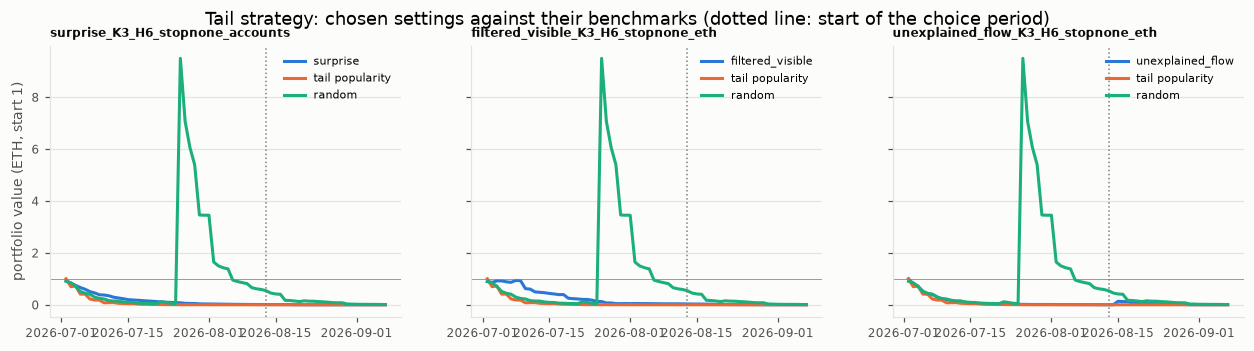

In [10]:
fig, axes = plt.subplots(1, len(chosen_tail), figsize=(14, 3.2), sharey=True)
for ax, (version, pick) in zip(axes, chosen_tail.items()):
    for slot, (label, setting) in enumerate(
        [(version, pick["setting"]), ("tail popularity", benchmark_setting(pick, "tail_popularity")), ("random", benchmark_setting(pick, "random"))]
    ):
        trades = tail_trades[tail_trades["setting"] == setting]
        equity = pf.equity_curve(trades, pick["holding_hours"])
        ax.plot(equity.index, equity.to_numpy(), color=plots.SERIES[slot], label=label)
    ax.axvline(db.CHOICE_START, color="grey", linestyle=":", linewidth=1)
    ax.axhline(1, color="grey", linewidth=0.5)
    ax.set_title(pick["setting"], fontsize=8)
    ax.legend(fontsize=7)
axes[0].set_ylabel("portfolio value (ETH, start 1)")
fig.suptitle("Tail strategy: chosen settings against their benchmarks (dotted line: start of the choice period)")
plt.show()

## 5. Launch momentum: the tuning grid

First the portfolio as planned in 12.6: each hourly decision puts its whole sleeve into its 1 or 3 positions.
The final value of every setting's portfolio on the tuning days:

In [11]:
def random_setting(row):
    ladder = "none" if row["ladder"] is None else f"{row['ladder'][0]}-{row['ladder'][1]}"
    return f"launch_random_N{row['min_buyers']}_K{row['k']}_H{row['holding_hours']}_ladder{ladder}"


final = {}
for row in launch_grid.to_dict("records"):
    part = db.in_period(launch_trades[launch_trades["setting"] == row["setting"]], *TUNE)
    final[row["setting"]] = pf.equity_curve(part, row["holding_hours"], interval_hours=1).iloc[-1]
final = pd.Series(final)
print(f"Settings whose portfolio ends below 0.001 of its start: {(final < 0.001).sum()} of {len(final)}")
print(f"Settings that end above their start: {(final > 1).sum()}")

Settings whose portfolio ends below 0.001 of its start: 108 of 108
Settings that end above their start: 0


A whole sleeve in one or three new tokens is the wrong size for a strategy that loses most positions: plan 12.8
asks for a small fixed fraction per position, set from half-Kelly. So, per setting and from its positions on the
tuning days: the hit rate, the mean and median position return, the mean without the three best positions, and
the **growth-optimal fraction** $f^*$, the share of capital per position that maximizes the mean of
$\ln(1 + f r)$ over the positions (searched from 0 to 0.5 in steps of 0.001), with the growth it gives.
$f^* = 0$ means no position size makes the setting grow.

In [12]:
def growth_optimal_fraction(returns):
    fractions = np.linspace(0, 0.5, 501)
    growth = np.array([np.log1p(f * returns).mean() for f in fractions])
    best = int(np.argmax(growth))
    return fractions[best], growth[best]


rows = []
for row in launch_grid.to_dict("records"):
    part = db.in_period(launch_trades[launch_trades["setting"] == row["setting"]], *TUNE)
    returns = part.loc[part["reason"] != "not entered", "net_return"].clip(lower=-1)
    f_best, g_best = growth_optimal_fraction(returns.to_numpy())
    rows.append({"setting": row["setting"], "version": row["version"], "positions": len(returns), "hit_rate": (returns > 0).mean(),
                 "mean": returns.mean(), "median": returns.median(), "mean_without_best_3": returns.sort_values().iloc[:-3].mean(),
                 "best_fraction": f_best, "growth_per_position": g_best, "final_value_full_sleeve": final[row["setting"]]})  # fmt: skip
launch_tune = pd.DataFrame(rows)
launch_tune.to_csv(OUT / "dev_launch_tuning_grid.csv", index=False)
print(f"Settings with a positive growth-optimal fraction: {(launch_tune['best_fraction'] > 0).sum()} of {len(launch_tune)}")
launch_tune.groupby("version")[["positions", "hit_rate", "mean", "median", "mean_without_best_3", "best_fraction"]].mean()

Settings with a positive growth-optimal fraction: 7 of 108


,positions,hit_rate,mean,median,mean_without_best_3,best_fraction
version,,,,,,
launch_momentum,799.8750,0.0334,-0.2935,-1.0000,-0.8644,0.0001
launch_random,887.7500,0.0318,-0.2165,-1.0000,-0.8466,0.0001


The settings with a positive growth-optimal fraction, and whether launch momentum does better than
`launch_random` at the same $N$, $K$, $H$ and ladder:

In [13]:
by_setting = launch_tune.set_index("setting")
launch_tune["random_mean"] = [by_setting.loc[random_setting(r), "mean"] if r["version"] == "launch_momentum" else np.nan
                              for r in launch_grid.to_dict("records")]  # fmt: skip
momentum = launch_tune[launch_tune["version"] == "launch_momentum"]
print(f"Momentum settings with a higher mean position return than random at the same settings: "
      f"{(momentum['mean'] > momentum['random_mean']).sum()} of {len(momentum)}")  # fmt: skip
launch_tune[launch_tune["best_fraction"] > 0].sort_values("growth_per_position", ascending=False)[
    ["setting", "positions", "hit_rate", "mean", "median", "mean_without_best_3", "best_fraction", "growth_per_position"]
]

Momentum settings with a higher mean position return than random at the same settings: 36 of 72


,setting,positions,hit_rate,mean,median,mean_without_best_3,best_fraction,growth_per_position
62,launch_momentum_N30_b0.7_K1_H72_laddernone,537,0.0112,14.2271,-1.0000,-0.9831,0.0020,0.0034
98,launch_random_N30_K1_H72_laddernone,748,0.0134,9.9971,-1.0000,-0.9515,0.0010,0.0021
71,launch_momentum_N30_b0.7_K3_H72_laddernone,807,0.0112,9.1964,-1.0000,-0.9656,0.0010,0.0018
53,launch_momentum_N30_b0.5_K3_H72_laddernone,950,0.0168,7.7714,-1.0000,-0.8968,0.0010,0.0015
107,launch_random_N30_K3_H72_laddernone,1054,0.0133,6.9044,-1.0000,-0.9085,0.0010,0.0013
59,launch_momentum_N30_b0.7_K1_H24_laddernone,537,0.0149,0.7367,-1.0000,-0.9390,0.0010,0.0003
95,launch_random_N30_K1_H24_laddernone,748,0.0160,0.3815,-1.0000,-0.9015,0.0010,0.0000


## 6. Launch momentum: what carries the positive settings

The best positions of the setting with the highest growth per position, over both periods.

In [14]:
top_setting = launch_tune.loc[launch_tune["growth_per_position"].idxmax(), "setting"]
chosen_trades = launch_trades[(launch_trades["setting"] == top_setting) & (launch_trades["reason"] != "not entered")]
profit = chosen_trades["net_return"].clip(lower=0).sort_values(ascending=False)
carrying = int((profit.cumsum() < profit.sum() / 2).sum()) + 1
print(f"{top_setting}: {carrying} of {len(chosen_trades):,} positions carry half of the gains (sum of positive net returns)")
chosen_trades.nlargest(10, "net_return")[["decision", "token", "size_eth", "net_return", "gross_return", "reason"]]

launch_momentum_N30_b0.7_K1_H72_laddernone: 1 of 912 positions carry half of the gains (sum of positive net returns)


,decision,token,size_eth,net_return,gross_return,reason
117522,2026-07-03 13:00:00+00:00,0x8f7b558ebee15d1bc7fda46ff2719c80418f844b,0.0193,"8,152.5253","9,867.5227",time
117548,2026-07-05 11:00:00+00:00,0xf3c188c493f05dc88d0ca5b7363d638400127b7f,0.0500,7.9521,10.5751,time
117785,2026-07-24 13:00:00+00:00,0x7ad7bc2f846c3af5d6f9de8fba0374b47c276c8b,0.0124,4.4379,6.1115,time
117752,2026-07-21 09:00:00+00:00,0x14cf64df75ceb97a65f160f3b39bca39eb6eeabc,0.0209,1.3568,2.0188,time
118272,2026-08-24 08:00:00+00:00,0x168b2c3385f30205056627da585d36bf30ad6cd8,0.0290,1.1867,1.3617,time
118239,2026-08-22 12:00:00+00:00,0x42778037d69350508cdd34d9fa17053970591101,0.0500,0.7305,0.8048,time
117918,2026-08-02 01:00:00+00:00,0x4c5fc2efd7f9fba2c6a9227abd9d1c3eefd6bdd7,0.0423,0.5450,0.8671,time
118270,2026-08-24 06:00:00+00:00,0xafceb5817668297a8b65b530d1c35d69cf26e9e8,0.0207,0.3591,0.7886,time
118396,2026-08-31 18:00:00+00:00,0x43ad2e007bf83ed42e9ca31d788b8519ce05cccc,0.0500,0.2034,0.3125,time
117595,2026-07-08 22:00:00+00:00,0x9c0cad96cb49e351262528ee9eab490c4245600a,0.0500,0.0807,0.1403,time


## 7. The proposed strategies

Written to `configs/wp8_strategy.json` as a **proposal** for the checkpoint with the authors (step 10). It is
not the freeze: `configs/wp8_frozen.json` and the tag `strategy-freeze` come only after that checkpoint.

In [15]:
def plain(value):
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, tuple):
        return list(value)
    return value


proposal = {
    "status": "proposal for the checkpoint of implementation plan 12.7 step 10; not frozen",
    "tail": {version: {k: plain(pick[k]) for k in ("setting", "k", "holding_hours", "stop", "weighting", "vs_tail_popularity", "standard_error")}
             for version, pick in chosen_tail.items()},  # fmt: skip
    "tail_choice_period": tail_choice.drop(columns=["setting"]).to_dict("records"),
    "launch": "no setting proposed: see section 5 (every full-sleeve portfolio ends near zero; positive growth-optimal fractions come from a few positions)",
    "trials": {"tail": TAIL_TRIALS, "launch": len(launch_tune)},
}
path = td.PROJECT_DIR.parent.parent / "configs" / "wp8_strategy.json"
path.write_text(json.dumps(proposal, indent=2, default=plain))
print(f"Written {path.name}")

Written wp8_strategy.json
